In [1]:
import warnings
warnings.filterwarnings('ignore')
import os
import scanpy as sc
import pandas as pd
import anndata as ad
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [2]:
in_dir = '../../results/03_kidney_atlas/02_create_anndata'
out_dir = '../../results/03_kidney_atlas/08_merge_celltypes'

os.makedirs(out_dir, exist_ok=True)

In [3]:
adata = sc.read_h5ad(f'{in_dir}/adata.h5ad')

In [4]:
adata

AnnData object with n_obs × n_vars = 203702 × 29732
    obs: 'library', 'nCount_RNA', 'nFeature_RNA', 'percent.er', 'percent.mt', 'degen.score', 'aEpi.score', 'aStr.score', 'cyc.score', 'matrisome.score', 'collagen.score', 'glycoprotein.score', 'proteoglycan.score', 'S.Score', 'G2M.Score', 'Phase', 'experiment', 'experiment.short', 'specimen', 'condition.long', 'condition.l1', 'condition.l2', 'condition.l3', 'patient', 'region.l1', 'region.l2', 'percent.cortex', 'percent.medulla', 'sex', 'race', 'tissue_type', 'assay', 'location', 'laterality', 'snDrop_predicted_subclass', 'snDrop_prediction_score', 'pagoda_k50_infomap', 'pagoda_k100_infomap', 'pagoda_k200_infomap', 'pagoda_k500_infomap', 'clusters', 'subclass.full', 'subclass.l3', 'subclass.l2', 'subclass.l1', 'state.l2', 'state.l1', 'class', 'structure'
    var: 'genes'
    uns: 'condition.l3_colors', 'laterality_colors', 'location_colors', 'patient_colors', 'structure_colors', 'subclass.l2_colors'
    obsm: 'X_umap'

In [5]:
adata.obs['subclass.l1'] = adata.obs['subclass.l1'].astype(str)
adata.obs['subclass.l2'] = adata.obs['subclass.l2'].astype(str)
adata = adata[adata.obs['subclass.l1'] != "nan"].copy()
adata = adata[adata.obs['subclass.l2'] != "nan"].copy()

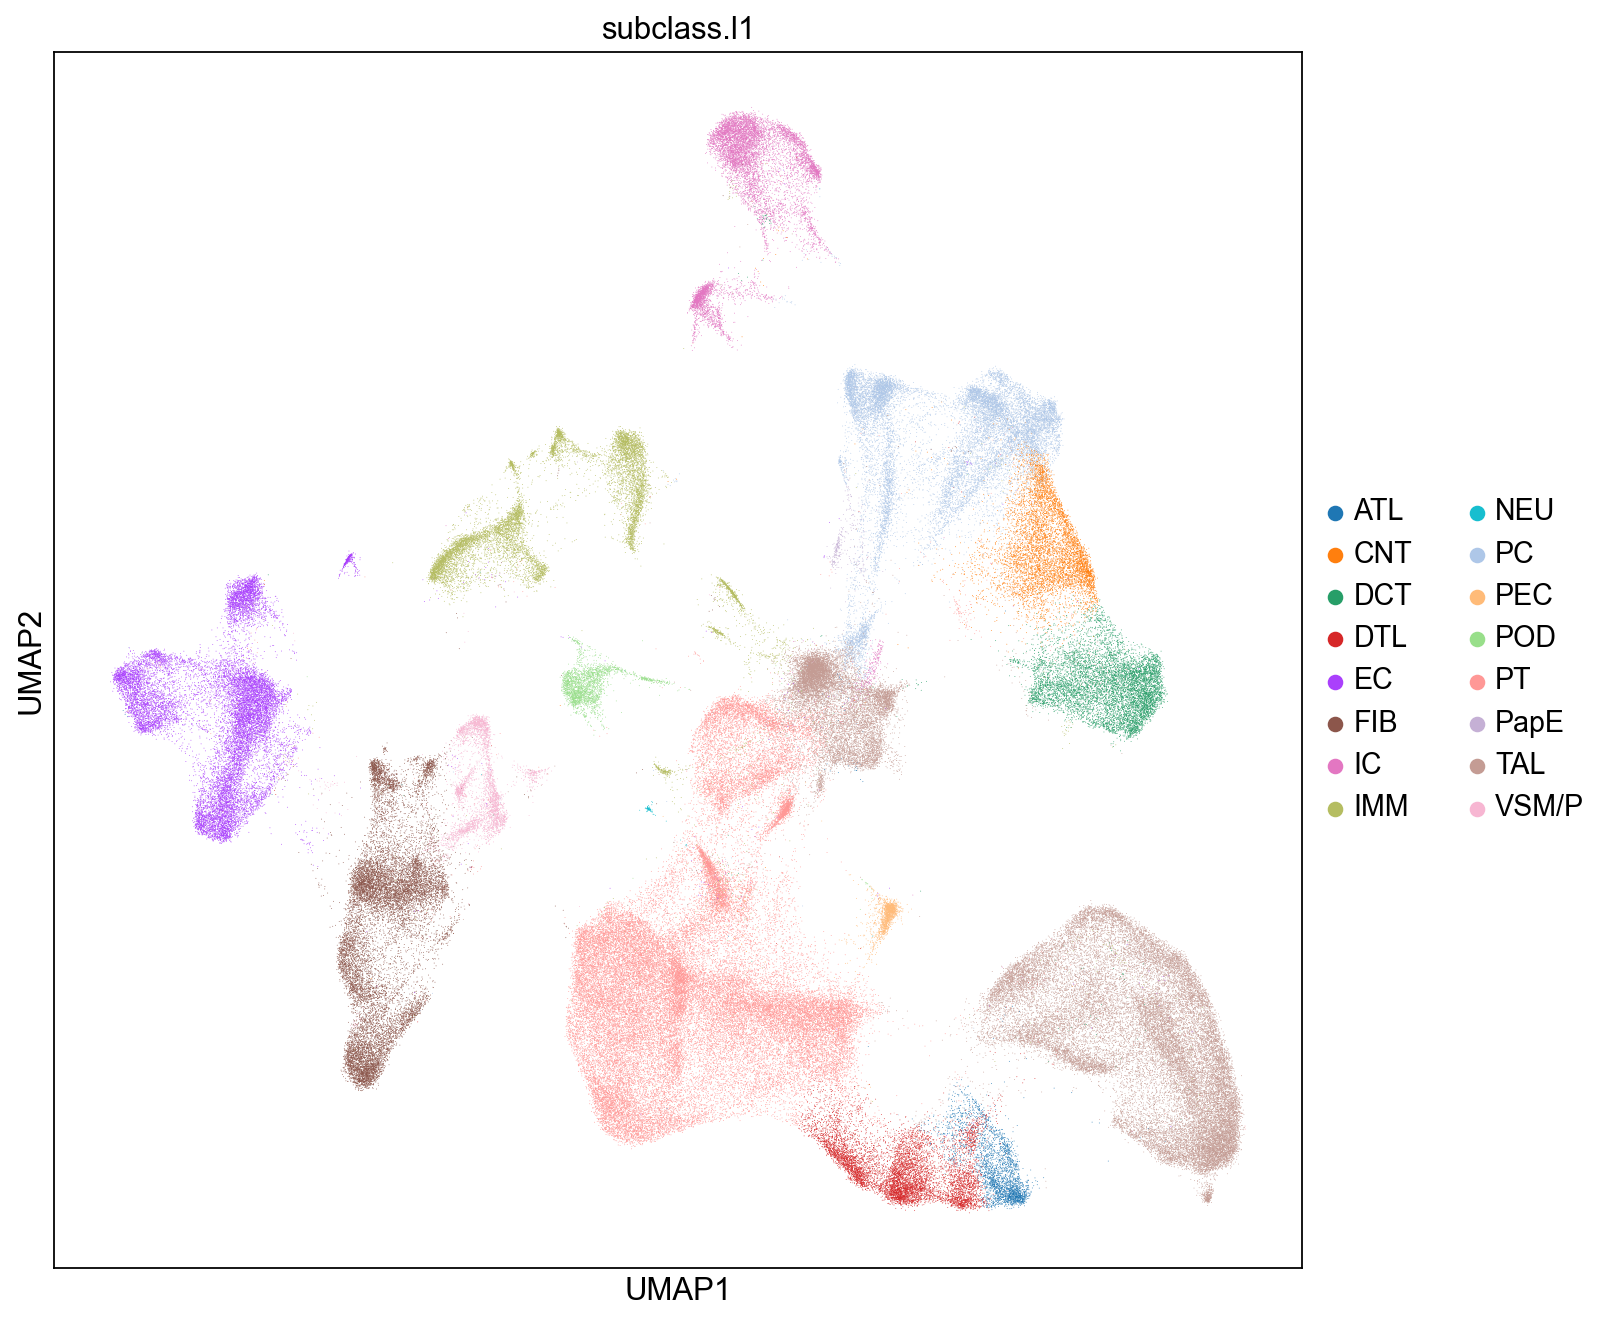

In [6]:
sc.set_figure_params(figsize=(10, 10))
sc.pl.umap(adata, color='subclass.l1')

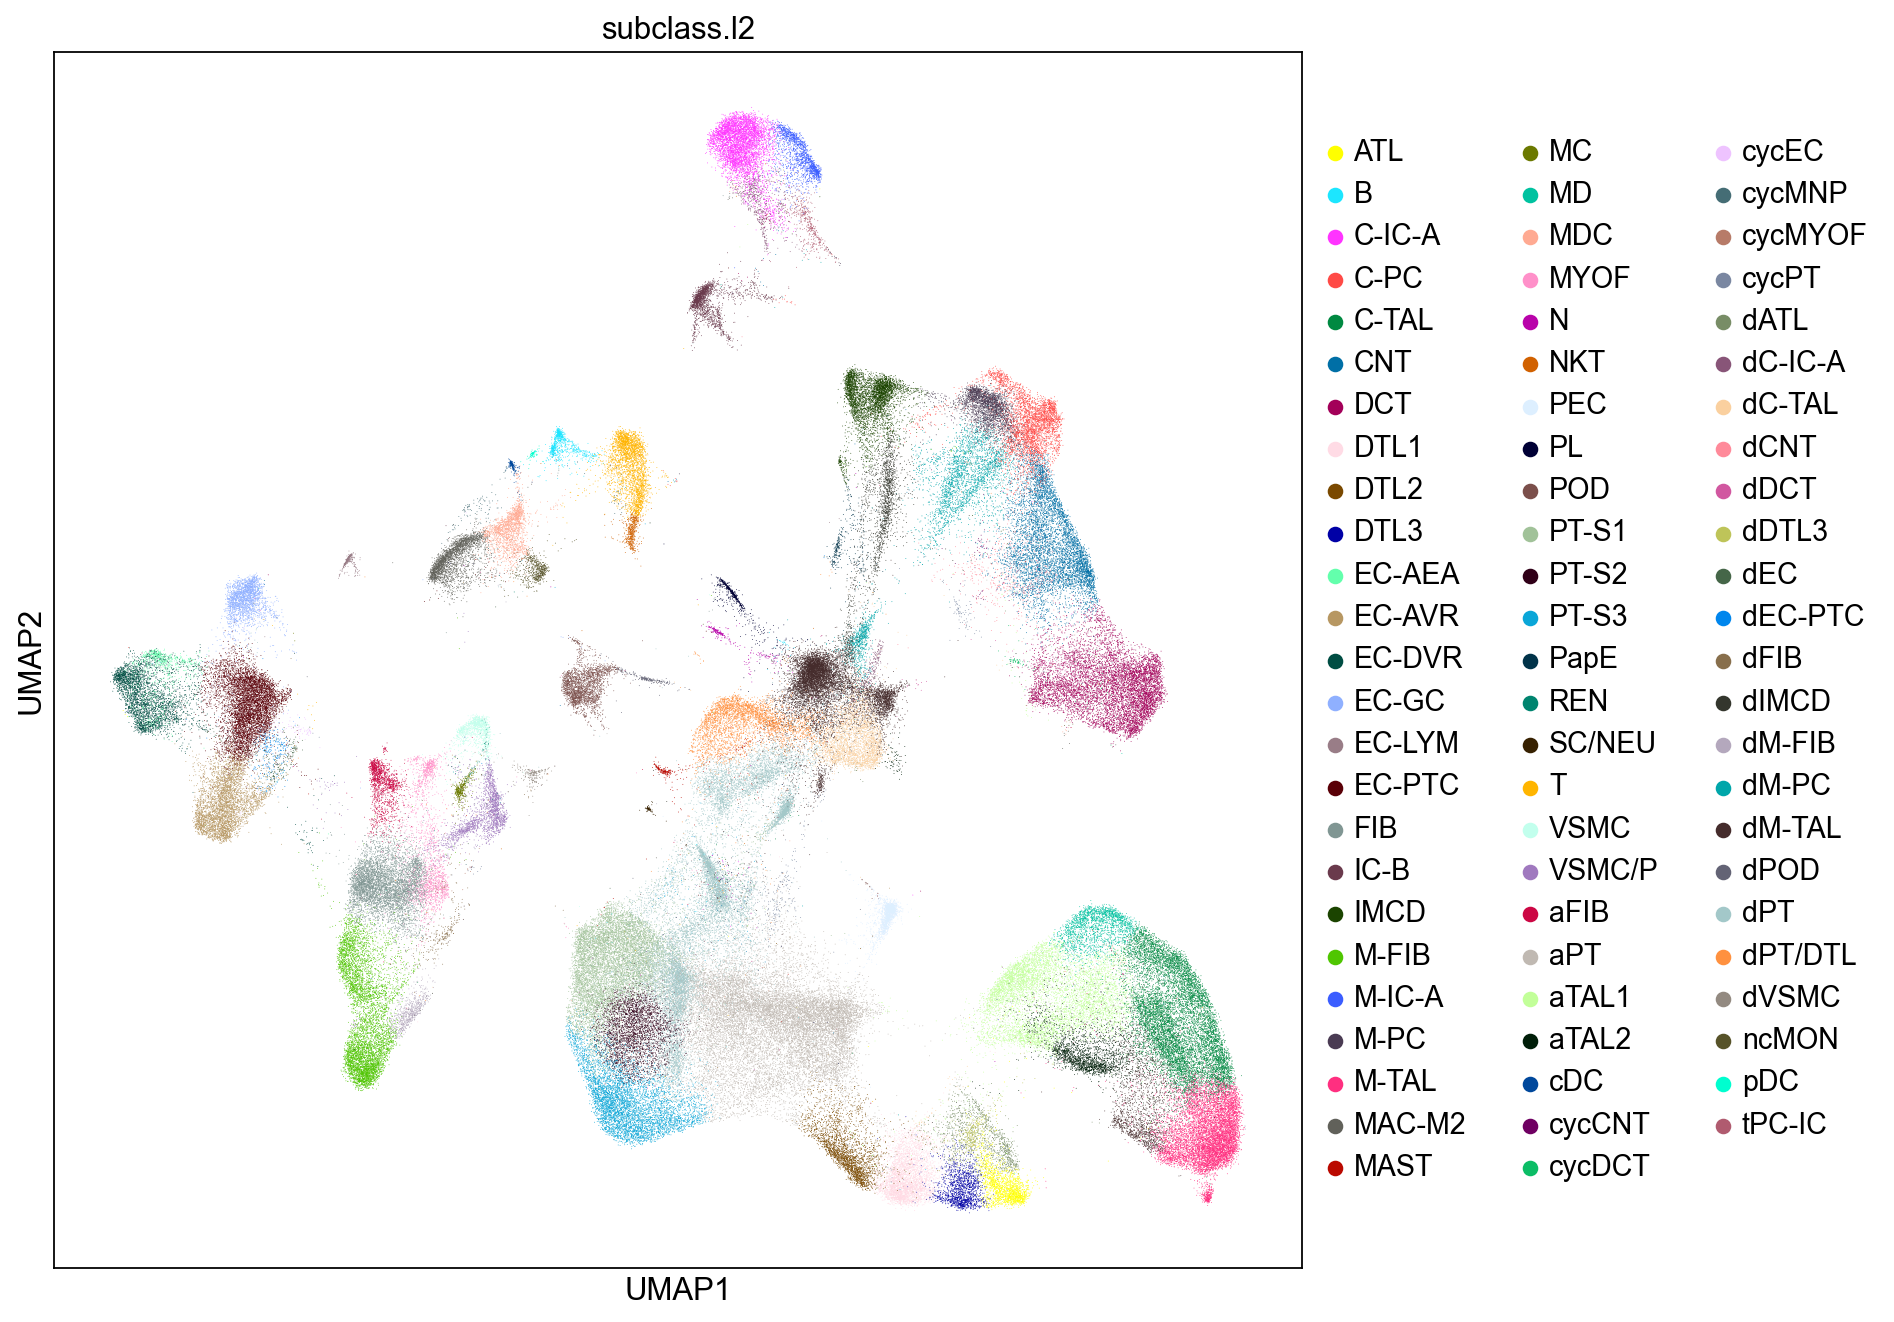

In [7]:
sc.pl.umap(adata, color='subclass.l2')

In [8]:
adata.obs["subclass.l2"].value_counts()

subclass.l2
aPT        15712
dPT        14431
dM-TAL     10781
C-TAL       9918
PT-S1       8543
           ...  
pDC           75
SC/NEU        72
cycCNT        68
cycMYOF       66
REN           61
Name: count, Length: 74, dtype: int64

In [8]:
adata.obs['cell_type'] = adata.obs['subclass.l2'].astype(str)

mapping = {
    'POD': 'POD', 'dPOD': 'POD', # Podocyte
    'PEC': 'PEC', # Parietal epithelial cell
    'PT-S1': 'PT', 'PT-S2': 'PT', 'PT-S3': 'PT', 'aPT': 'PT', # Proximal tubule
    'cycPT': 'PT', 'dPT': 'PT', 'dPT/DTL': 'PT', # Proximal tubule
    'DTL2': 'DTL', 'DTL1': 'DTL', 'DTL3': 'DTL', 'dDTL3': 'DTL', # Descending thin limb
    'ATL': 'ATL', 'dATL': 'ATL', 
    'aTAL1': 'TAL', 'aTAL2': 'TAL', 'M-TAL': 'TAL', 
    'dM-TAL': 'TAL', 'C-TAL': 'TAL', 'dC-TAL': 'TAL', 'MD': 'TAL', # Ascending thin limb
    'dDCT': 'DCT', 'cycDCT': 'DCT', # Distal tubules
    'dCNT': 'CNT', 'cycCNT': 'CNT', # Connecting tubules
    'C-PC': 'PC', 'M-PC': 'PC', 'dM-PC': 'PC', 'IMCD': 'PC', 'dIMCD': 'PC', # Principal cells
    'C-IC-A': 'IC', 'dC-IC-A': 'IC', 'M-IC-A': 'IC', 'tPC-IC': 'IC', 'IC-B': 'IC', # Intercalated cells
    'EC-GC': 'EC', 'EC-AEA': 'EC', 'EC-DVR': 'EC', 'EC-PTC': 'EC', 'dEC-PTC': 'EC',
    'EC-AVR': 'EC', 'dEC': 'EC', 'cycEC': 'EC', 'EC-LYM': 'EC', # Endothelial cells
    'MC': 'VSM_P', 'REN': 'VSM_P', 'VSMC': 'VSM_P', 'VSMC/P': 'VSM_P', 'dVSMC': 'VSM_P', # Vascular smooth muscle and pericytes
    'MYOF': 'FIB', 'cycMYOF': 'FIB', 'M-FIB': 'FIB', 'dM-FIB': 'FIB', 'aFIB': 'FIB', 'dFIB': 'FIB',
    'SC/NEU': 'NEU',
    'B': 'IMM_B',
    'PL': 'IMM_PL',
    'T': 'IMM_T',
    'NKT': 'IMM_NKT',
    'MAST': 'IMM_MAST',
    'MAC-M2': 'IMM_MAC_M2',
    'cycMNP': 'IMM_cycMNP',
    'MDC': 'IMM_MDC',
    'cDC': 'IMM_cDC',
    'pDC': 'IMM_pDC',
    'ncMON': 'IMM_ncMON',
    'N': 'IMM_N',
}

adata.obs['cell_type'] = adata.obs['cell_type'].map(mapping).fillna(adata.obs['cell_type'])

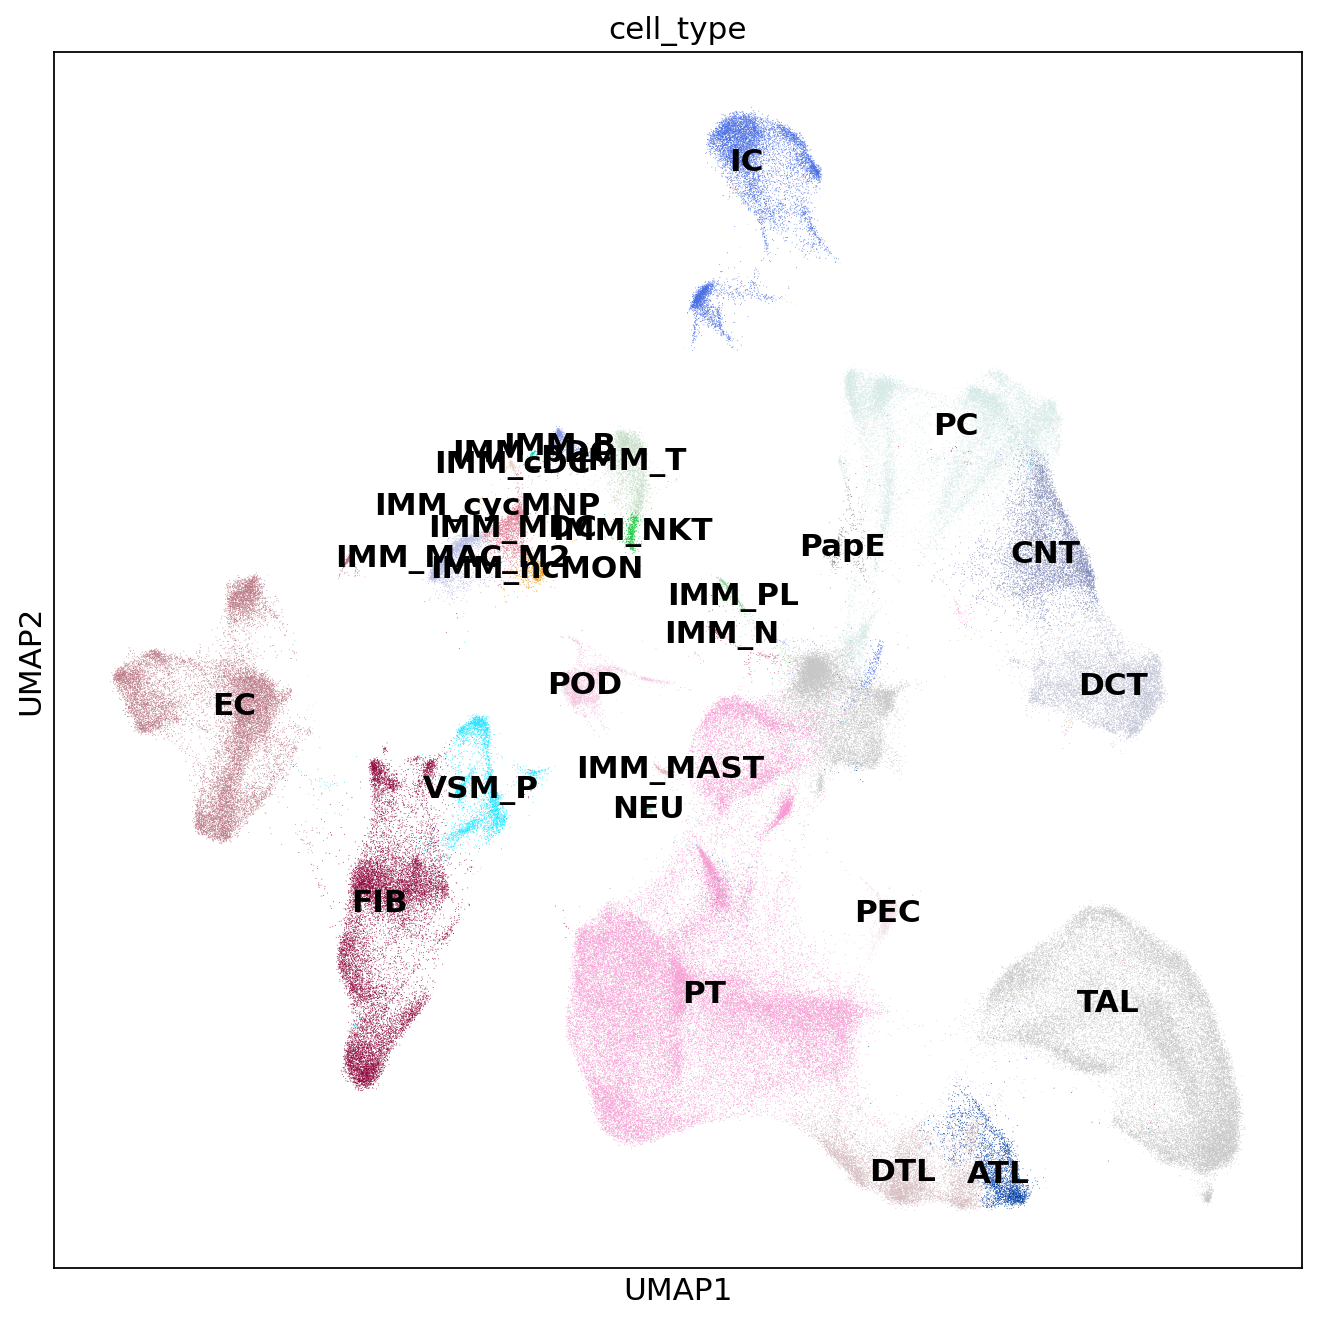

In [11]:
sc.set_figure_params(figsize=(10, 10))
sc.pl.umap(adata, color=['cell_type'], legend_loc='on data')

In [10]:
adata.write_h5ad(f'{out_dir}/adata.h5ad')